# 01: First look at my FACEIT data

138 CS2 matches on FACEIT. Before any modelling: what does the data actually say?

Match-level only (scoreboard stats). Round-by-round detail comes later from demos.

> 📝 = space for my own take. Fill these in. That's the bit that makes it mine.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
DATA = ROOT / "data" / "processed" / "matches.parquet"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

if not DATA.exists():
    import build_dataset
    build_dataset.build().to_parquet(DATA, index=False)

df = pd.read_parquet(DATA)
df["map"] = df["map"].str.replace("de_", "", regex=False).str.title()

plt.rcParams.update({
    "figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
})
WIN, LOSS, NEUTRAL = "#2a9d8f", "#e76f51", "#6c757d"

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def wilson(wins, n, z=1.96):
    """95% interval for a win rate. Small samples = wide intervals; keep me honest."""
    if n == 0:
        return (np.nan, np.nan)
    p = wins / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return centre - half, centre + half

def winrate_table(frame, by):
    g = frame.groupby(by, observed=True)["won"].agg(n="size", wins="sum")
    g["win_rate"] = g["wins"] / g["n"]
    ci = g.apply(lambda r: wilson(r["wins"], r["n"]), axis=1)
    g["ci_low"] = [c[0] for c in ci]
    g["ci_high"] = [c[1] for c in ci]
    return g.round(3)

print(f"{len(df)} matches, {df['started_at_local'].min():%d %b %Y} -> {df['started_at_local'].max():%d %b %Y}")

138 matches, 19 Jun 2025 -> 08 Nov 2026


## 1. The headline numbers

In [2]:
overview = pd.Series({
    "matches": len(df),
    "wins": int(df["won"].sum()),
    "losses": int((~df["won"]).sum()),
    "win rate": f"{df['won'].mean():.1%}",
    "K/D (total)": round(df["kills"].sum() / df["deaths"].sum(), 2),
    "avg ADR": round(df["adr"].mean(), 1),
    "avg HS%": round(df["headshots_pct"].mean(), 1),
    "top-fragged my team": f"{(df['team_kill_rank'] == 1).mean():.0%} of matches",
    "level at start -> now": f"{df['my_level'].dropna().iloc[0]:.0f} -> {df['my_level'].dropna().iloc[-1]:.0f}",
    "sessions": df["session_id"].nunique(),
})
overview.to_frame("value")

,value
matches,138
wins,73
losses,65
win rate,52.9%
K/D (total),1.25
avg ADR,92.1
avg HS%,48.2
top-fragged my team,43% of matches
level at start -> now,4 -> 7
sessions,76


> 📝 **My take:** the stats don't surprise me. It just *feels* like my team is very disjointed, especially on T side, and we only win if I pop off (or maybe my friend Sad_X does). → checked in section 9.

## 2. The climb: level and form over time

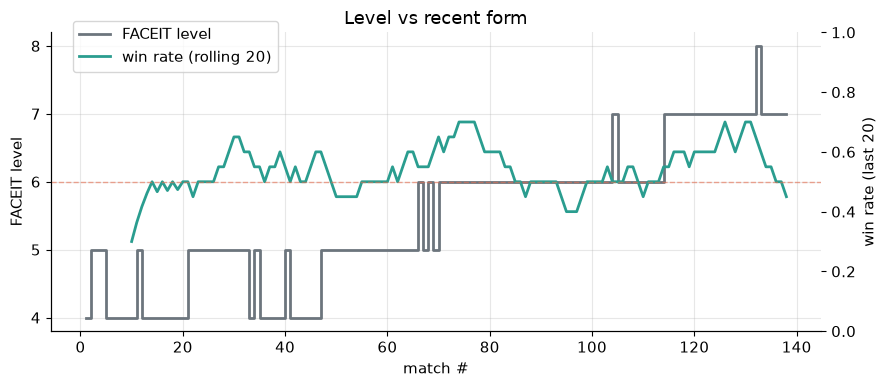

In [3]:
fig, ax1 = plt.subplots()
# a few matches have no level recorded (API returns 0); carry the last known level forward
ax1.step(df["match_no"], df["my_level"].ffill(), where="post", color=NEUTRAL, lw=2, label="FACEIT level")
ax1.set_xlabel("match #")
ax1.set_ylabel("FACEIT level")
ax1.set_yticks(range(int(df["my_level"].min()), int(df["my_level"].max()) + 1))

ax2 = ax1.twinx()
roll = df["won"].rolling(20, min_periods=10).mean()
ax2.plot(df["match_no"], roll, color=WIN, lw=2, label="win rate (rolling 20)")
ax2.axhline(0.5, color=LOSS, ls="--", lw=1, alpha=0.6)
ax2.set_ylim(0, 1)
ax2.set_ylabel("win rate (last 20)")
ax2.grid(False)
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.95))
ax1.set_title("Level vs recent form")
save("01_level_and_form")

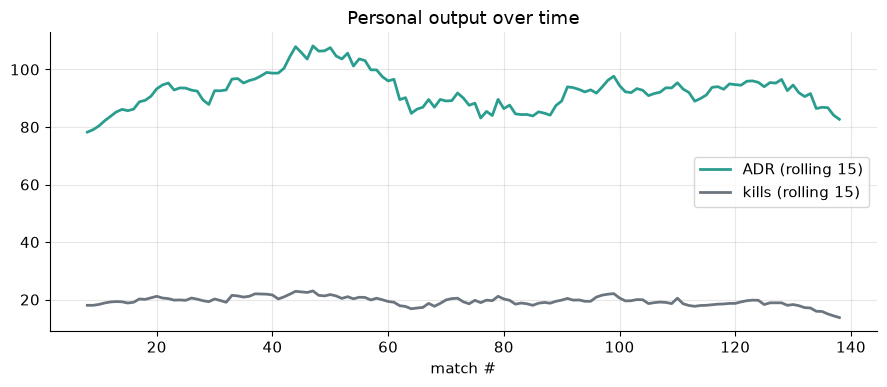

In [4]:
# rolling performance: am I actually playing better, or just getting carried up?
fig, ax = plt.subplots()
for col, color, label in [("adr", WIN, "ADR"), ("kills", NEUTRAL, "kills")]:
    ax.plot(df["match_no"], df[col].rolling(15, min_periods=8).mean(), color=color, lw=2, label=f"{label} (rolling 15)")
ax.set_xlabel("match #")
ax.legend()
ax.set_title("Personal output over time")
save("01_output_over_time")

> 📝 **My take:** not sure what changed around the level jumps. Maybe the data can tell me (see section 10).

## 3. Maps

In [5]:
maps = winrate_table(df, "map").sort_values("n", ascending=False)
perf = df.groupby("map").agg(kd=("k_d_ratio", "mean"), adr=("adr", "mean"))
maps = maps.join(perf.round(2))
maps

,n,wins,win_rate,ci_low,ci_high,kd,adr
map,,,,,,,
Mirage,53,36,0.679,0.545,0.789,1.35,94.32
Dust2,25,12,0.480,0.300,0.665,1.28,89.36
Inferno,23,13,0.565,0.368,0.744,1.47,100.35
Ancient,13,4,0.308,0.127,0.576,0.96,76.25
Nuke,10,4,0.400,0.168,0.687,1.14,81.76
Anubis,7,0,0.000,0.000,0.354,1.06,89.69
Cache,4,4,1.000,0.510,1.000,2.04,117.40
Overpass,2,0,0.000,0.000,0.658,1.06,82.60
Train,1,0,0.000,0.000,0.793,1.31,92.00


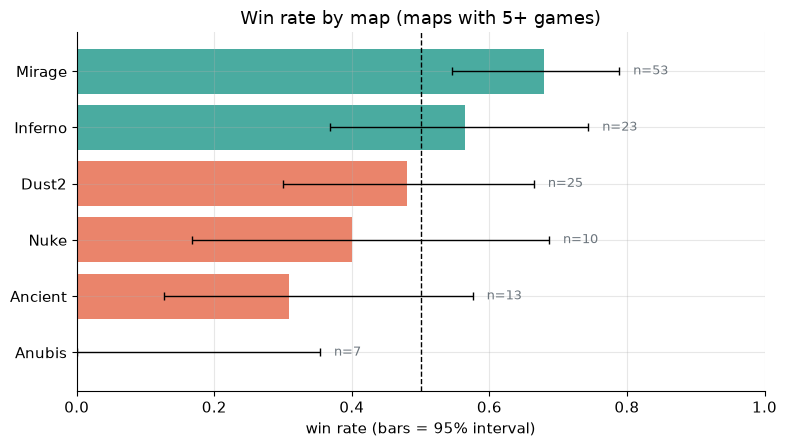

In [6]:
m = maps[maps["n"] >= 5].sort_values("win_rate")
fig, ax = plt.subplots(figsize=(8, 0.6 * len(m) + 1))
colors = [WIN if w >= 0.5 else LOSS for w in m["win_rate"]]
ax.barh(m.index, m["win_rate"], color=colors, alpha=0.85)
ax.errorbar(m["win_rate"], m.index, xerr=[m["win_rate"] - m["ci_low"], m["ci_high"] - m["win_rate"]],
            fmt="none", color="black", capsize=3, lw=1)
for y, (hi, n) in enumerate(zip(m["ci_high"], m["n"])):
    ax.text(hi + 0.02, y, f"n={n}", va="center", color=NEUTRAL, fontsize=9)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_xlim(0, 1)
ax.set_xlabel("win rate (bars = 95% interval)")
ax.set_title("Win rate by map (maps with 5+ games)")
save("01_maps")

Error bars are wide: with ~10–25 games on most maps, a 60% vs 45% gap is often just noise. Mirage is the only map with a decent sample.

> 📝 **My take:** my lower-ranked friends are more comfortable on the big 3 (Mirage, Dust2, Inferno), so that's mostly what we play. That's also why the other maps have so few games.

## 4. What's different when I win vs lose?

In [7]:
cols = {
    "kills": "kills", "deaths": "deaths", "assists": "assists", "adr": "ADR",
    "k_d_ratio": "K/D", "headshots_pct": "HS%", "first_kills": "first kills",
    "entry_count": "entry attempts", "entry_wins": "entry wins",
    "utility_damage": "utility dmg", "enemies_flashed": "enemies flashed",
    "flash_count": "flashes thrown", "clutch_kills": "clutch kills", "team_kill_rank": "kill rank on team",
}
cmp = df.groupby("won")[list(cols)].mean().T.rename(index=cols, columns={False: "loss", True: "win"})
cmp["diff"] = cmp["win"] - cmp["loss"]
# scale by spread so stats with different units are comparable
cmp["effect (std)"] = cmp["diff"] / df[list(cols)].std().rename(index=cols)
cmp.round(2).sort_values("effect (std)", key=abs, ascending=False)

won,loss,win,diff,effect (std)
K/D,1.04,1.54,0.50,0.89
deaths,16.86,13.93,-2.93,-0.64
ADR,86.72,96.82,10.10,0.45
clutch kills,2.22,1.45,-0.76,-0.40
kills,17.83,20.27,2.44,0.32
first kills,2.32,2.85,0.53,0.30
entry wins,2.32,2.84,0.51,0.29
assists,5.14,5.86,0.72,0.26
utility dmg,65.45,81.62,16.17,0.20
flashes thrown,11.25,12.38,1.14,0.16


Careful with this one: of course I have more kills in games we win. Part of that is *because* we won (more rounds, better economy, more to shoot at). It's correlation, not "do X to win". Untangling that needs round-level data.

Clutch kills are *higher* in losses, probably because when the team's losing I'm the last one alive more often.

## 5. How do my games end? Stomps vs close ones

close games (≤3 rounds): 45, win rate 53%
stomps either way (≥8 rounds): 37


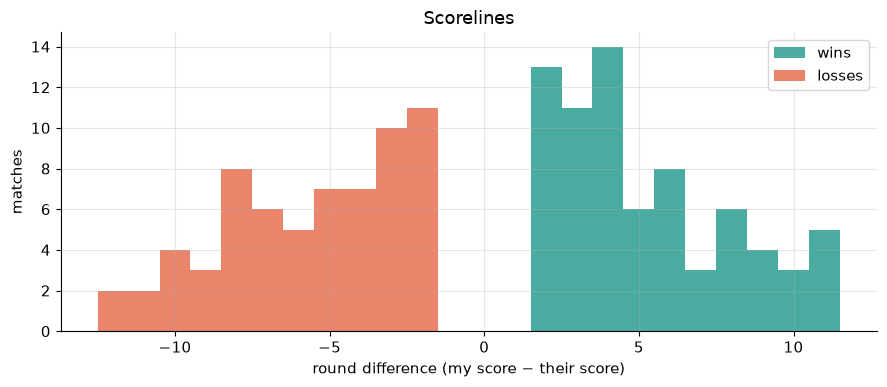

In [8]:
fig, ax = plt.subplots()
bins = np.arange(df["round_diff"].min() - 0.5, df["round_diff"].max() + 1.5)
ax.hist(df.loc[df["won"], "round_diff"], bins=bins, color=WIN, alpha=0.85, label="wins")
ax.hist(df.loc[~df["won"], "round_diff"], bins=bins, color=LOSS, alpha=0.85, label="losses")
ax.set_xlabel("round difference (my score − their score)")
ax.set_ylabel("matches")
ax.legend()
ax.set_title("Scorelines")
save("01_scorelines")

close = df["round_diff"].abs() <= 3
print(f"close games (≤3 rounds): {close.sum()}, win rate {df.loc[close, 'won'].mean():.0%}")
print(f"stomps either way (≥8 rounds): {(df['round_diff'].abs() >= 8).sum()}")

## 6. The tilt check 🧊

The one-liner is *"the chill guy who never gets angry"*. Let's test it. If I'm really unbothered, losing the previous game in a session shouldn't change how I play the next one.

In [9]:
s = df.dropna(subset=["prev_won"]).copy()
s["after"] = s["prev_won"].map({True: "after a win", False: "after a loss"})
tilt = winrate_table(s, "after").join(s.groupby("after")[["k_d_ratio", "adr"]].mean().round(2))
tilt

,n,wins,win_rate,ci_low,ci_high,k_d_ratio,adr
after,,,,,,,
after a loss,26,13,0.500,0.321,0.679,1.28,95.10
after a win,36,19,0.528,0.370,0.680,1.22,86.08


In [10]:
df["game_bucket"] = pd.cut(df["game_in_session"], [0, 1, 2, 3, 99], labels=["1st", "2nd", "3rd", "4th+"])
winrate_table(df, "game_bucket").join(df.groupby("game_bucket", observed=True)[["k_d_ratio", "adr"]].mean().round(2))

,n,wins,win_rate,ci_low,ci_high,k_d_ratio,adr
game_bucket,,,,,,,
1st,76,41,0.539,0.428,0.647,1.36,93.86
2nd,41,20,0.488,0.343,0.635,1.28,92.15
3rd,15,11,0.733,0.480,0.891,1.17,81.41
4th+,6,1,0.167,0.030,0.564,1.18,95.33


Small samples again, so check the intervals before declaring anything. Either answer is a good story: *"turns out I really am chill"* or *"turns out I tilt and didn't know it"*.

> 📝 **My take:** after losing a game nothing much changes. If it's a string of bad losses, we just go play something else. Chill guy status: confirmed (for now).

## 7. Solo vs with the regulars

In [11]:
counts = df["teammates"].explode().value_counts()
print("teammates I've played 5+ games with:", (counts >= 5).sum())
winrate_table(df, "n_regulars").join(df.groupby("n_regulars")[["k_d_ratio", "adr"]].mean().round(2))

teammates I've played 5+ games with: 6


,n,wins,win_rate,ci_low,ci_high,k_d_ratio,adr
n_regulars,,,,,,,
0,3,2,0.667,0.208,0.939,1.60,82.63
1,25,15,0.600,0.407,0.766,1.37,90.40
2,27,15,0.556,0.373,0.724,1.26,94.39
3,45,22,0.489,0.350,0.630,1.35,94.58
4,38,19,0.500,0.348,0.652,1.23,89.27


*Regulars* = anyone who's been on my team 5+ times, as a stand-in for party/stack size, since the API's `premade` flag is always empty in my data.

> 📝 **My take:** they're all irl friends. Which one do I win the most with? → section 9.

## 8. Were we the better team on paper?

In [12]:
df["gap_bucket"] = pd.cut(df["level_gap"], [-10, -0.5, 0.5, 10],
                          labels=["we were lower", "roughly even", "we were higher"])
winrate_table(df, "gap_bucket")

,n,wins,win_rate,ci_low,ci_high
gap_bucket,,,,,
we were lower,17,8,0.471,0.262,0.690
roughly even,102,59,0.578,0.481,0.670
we were higher,14,3,0.214,0.076,0.476


Average FACEIT level of my team minus theirs, at the time of the match.

## 9. Who carries? 🫡

*"We only win if I pop off, or Sad_X does."* Let's check. One row per player per match, my team only.

In [13]:
mates = pd.read_parquet(ROOT / "data" / "processed" / "teammates.parquet")
games_with = mates.loc[~mates["is_me"], "player_id"].value_counts()
regular_ids = set(games_with[games_with >= 5].index)
nick = mates.groupby("player_id")["nickname"].last()

def who(row):
    if row["is_me"]:
        return "me"
    return nick[row["player_id"]] if row["player_id"] in regular_ids else "random (5th stack)"

mates["who"] = mates.apply(who, axis=1)

per_person = (mates[mates["who"] != "random (5th stack)"]
    .groupby("who")
    .agg(games=("won", "size"), win_rate=("won", "mean"), top_frag_pct=("is_top_frag", "mean"),
         kills=("kills", "sum"), deaths=("deaths", "sum"), adr=("adr", "mean"))
    .assign(kd=lambda d: d["kills"] / d["deaths"])
    .drop(columns=["kills", "deaths"])
    .sort_values("games", ascending=False))
per_person.round(2)

,games,win_rate,top_frag_pct,adr,kd
who,,,,,
me,138,0.53,0.41,92.06,1.25
Toe_bias,105,0.53,0.07,67.78,0.83
Sad_X,80,0.52,0.30,90.99,1.20
Inbail,75,0.49,0.25,80.78,0.98
XxcanonboixX,75,0.52,0.13,75.25,0.92
JustAJerky,16,0.44,0.00,57.68,0.64
Claredee0p,14,0.36,0.00,40.14,0.46


In [14]:
# when X top-frags, how often do we win?
top = mates[mates["is_top_frag"]]
carry = winrate_table(top, "who").sort_values("n", ascending=False)
carry

,n,wins,win_rate,ci_low,ci_high
who,,,,,
me,56,25,0.446,0.324,0.576
Sad_X,24,13,0.542,0.351,0.721
random (5th stack),22,18,0.818,0.615,0.927
Inbail,19,9,0.474,0.273,0.683
XxcanonboixX,10,4,0.400,0.168,0.687
Toe_bias,7,4,0.571,0.250,0.842


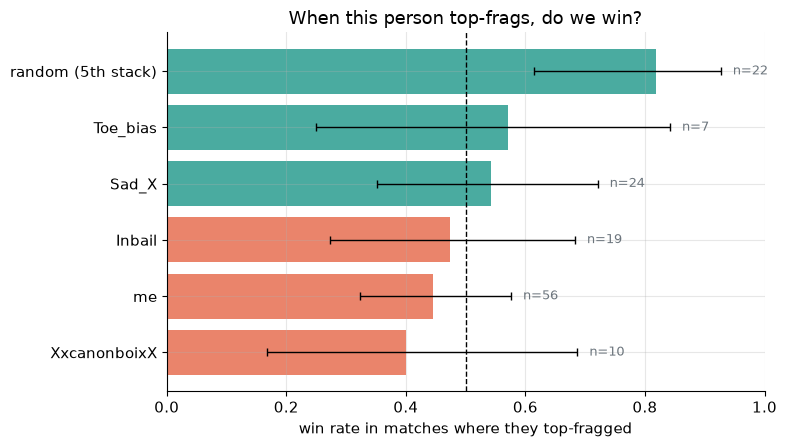

In [15]:
c = carry[carry["n"] >= 5].sort_values("win_rate")
fig, ax = plt.subplots(figsize=(8, 0.6 * len(c) + 1))
ax.barh(c.index, c["win_rate"], color=[WIN if w >= 0.5 else LOSS for w in c["win_rate"]], alpha=0.85)
ax.errorbar(c["win_rate"], c.index, xerr=[c["win_rate"] - c["ci_low"], c["ci_high"] - c["win_rate"]],
            fmt="none", color="black", capsize=3, lw=1)
for y, (hi, n) in enumerate(zip(c["ci_high"], c["n"])):
    ax.text(hi + 0.02, y, f"n={n}", va="center", color=NEUTRAL, fontsize=9)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_xlim(0, 1)
ax.set_xlabel("win rate in matches where they top-fragged")
ax.set_title("When this person top-frags, do we win?")
save("01_who_carries")

**Reading this:** me top-fragging is *not* a win condition. It happens a lot in losses (me farming kills while the team falls apart). The best sign is the random 5th player top-fragging: that means the whole team had a decent game, not just one carry.

> 📝 **My take:** it could also be because I have a higher floor? So when I'm not top-fragging, it's still possible I'm doing well. Which means more people are doing well, so we're probably winning?

### Checking my higher-floor theory

In [16]:
# (1) how bad are each regular's bad games? 10th percentile ADR = their 'floor'
reg = mates[mates["who"] != "random (5th stack)"]
floor = reg.groupby("who")["adr"].agg(games="size", avg_adr="mean", floor_adr_p10=lambda a: a.quantile(0.1)).round(1)
display(floor.sort_values("floor_adr_p10", ascending=False))

# (2) win rate by how many of us had a K/D of 1 or more
mates["kd_1plus"] = mates["k_d_ratio"] >= 1
n_good = mates.groupby("match_id").agg(players_kd_1plus=("kd_1plus", "sum"), won=("won", "first"))
display(winrate_table(n_good, "players_kd_1plus"))

me_rows = mates[mates["is_me"]]
not_top = me_rows[~me_rows["is_top_frag"]]
print(f"games where I did NOT top-frag: {len(not_top)}, win rate {not_top['won'].mean():.0%}, "
      f"my ADR {not_top['adr'].mean():.0f}, my K/D >= 1 in {not_top['kd_1plus'].mean():.0%} of them")

,games,avg_adr,floor_adr_p10
who,,,
me,138,92.1,65.9
Sad_X,80,91.0,63.6
Inbail,75,80.8,56.7
XxcanonboixX,75,75.2,54.2
Toe_bias,105,67.8,44.9
JustAJerky,16,57.7,42.7
Claredee0p,14,40.1,29.2


,n,wins,win_rate,ci_low,ci_high
players_kd_1plus,,,,,
0,15,0,0.000,-0.000,0.204
1,18,4,0.222,0.090,0.452
2,32,9,0.281,0.156,0.454
3,35,23,0.657,0.492,0.792
4,28,27,0.964,0.823,0.994
5,10,10,1.000,0.722,1.000


games where I did NOT top-frag: 82, win rate 59%, my ADR 82, my K/D >= 1 in 55% of them


**The data backs it up.** My floor (10th-percentile ADR ~66) is the highest of the regulars (just ahead of Sad_X at ~64), and when I'm *not* top-fragging I still have a K/D of 1+ in about half those games, and we win 59% of them.
What really predicts the win is **how many of us have a decent game**: with 2 players on K/D ≥ 1 we win ~28%, with 3 it's ~66%, with 4 it's ~96%.
So "me top-fragging" is a bad sign mostly because it often means I'm the *only* one doing well.

## 10. Did I stop entrying?

*"I stopped entrying in the last 10–15 games. At level 7–8 entrying felt harder and my team is hopeless when I'm dead, so I play more passive."*

FACEIT's "entry" = being in the **first duel of the round** (opening kill or opening death), whether I meant to or not.

In [17]:
df["entry_per_round"] = df["entry_count"] / df["rounds"]
df["entry_success"] = df["entry_wins"] / df["entry_count"].where(df["entry_count"] > 0)
df["period"] = pd.cut(df["match_no"], [0, 50, 100, len(df) - 15, len(df)],
                      labels=["1–50", "51–100", f"101–{len(df) - 15}", "last 15"])
entry = df.groupby("period", observed=True).agg(
    n=("won", "size"), win_rate=("won", "mean"),
    opening_duels_per_round=("entry_per_round", "mean"), opening_duel_win_pct=("entry_success", "mean"),
    first_kills=("first_kills", "mean"), kd=("k_d_ratio", "mean"), adr=("adr", "mean"))
entry.round(3)

,n,win_rate,opening_duels_per_round,opening_duel_win_pct,first_kills,kd,adr
period,,,,,,,
1–50,50,0.500,0.224,0.551,2.920,1.424,95.840
51–100,50,0.560,0.188,0.585,2.540,1.241,89.176
101–123,23,0.609,0.198,0.574,2.304,1.355,96.252
last 15,15,0.400,0.243,0.528,2.200,1.065,82.673


opening-duel win % in wins vs losses: {False: 0.485, True: 0.634}


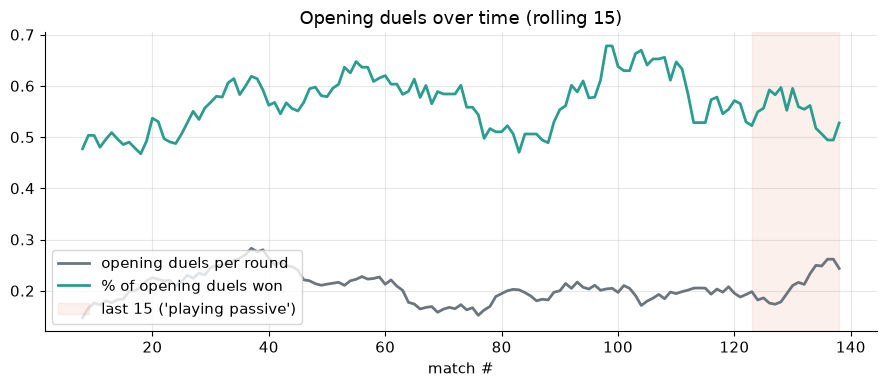

In [18]:
fig, ax = plt.subplots()
ax.plot(df["match_no"], df["entry_per_round"].rolling(15, min_periods=8).mean(), color=NEUTRAL, lw=2,
        label="opening duels per round")
ax.plot(df["match_no"], df["entry_success"].rolling(15, min_periods=8).mean(), color=WIN, lw=2,
        label="% of opening duels won")
ax.axvspan(len(df) - 15, len(df), color=LOSS, alpha=0.1, label="last 15 ('playing passive')")
ax.set_xlabel("match #")
ax.legend(loc="lower left")
ax.set_title("Opening duels over time (rolling 15)")
save("01_entry_over_time")

print("opening-duel win % in wins vs losses:", df.groupby("won")["entry_success"].mean().round(3).to_dict())

**Reading this:** in the last 15 I'm *not* in fewer opening duels; if anything I'm in slightly more, but I'm winning fewer of them, with fewer first kills and a lower K/D. One possible story: playing passive doesn't avoid the first fight, it just means the first fight happens on the enemy's terms (getting picked instead of picking). 15 games is a small sample, though, and only demos can show *where* and *how* those duels happen.

> 📝 **My take:** so should my team be playing aggressive on T and CT side?

→ Checked with the demos in notebook 02, section 8. Short version: not really. Winning the first fight (and having it traded) matters much more than how early it happens.

## So far

> 📝 Write 3–5 bullets in my own words: what surprised me, what I believed that the data didn't back up, what I want to dig into next.

**Limits of match-level data:** these are scoreboard totals, so they can't say *why* rounds are lost: economy, utility timing, positioning, trades. That needs demos.